In [2]:
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [3]:
df = pd.read_csv('Fish.csv')
df.head()

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


In [9]:
#now we want to train model on 6 variables i.e. length1 length2 length3 height witdth and species
X_tr = df[['Species','Length1','Length2','Length3','Height','Width']]
y_te = df['Weight']
print('shape',df.shape)
print('any null:',df.isnull().sum())


shape (159, 7)
any null: Species    0
Weight     0
Length1    0
Length2    0
Length3    0
Height     0
Width      0
dtype: int64


No column has an empty value so no need to fill with any kind of average or median

In [10]:
#we have to prepocess data because species has the data type categorical so we have to convert it into binary
#so that linear regression could comprehend
prepoce = ColumnTransformer(transformers=
    [('species',OneHotEncoder(handle_unknown='ignore'),["Species"])],#onehotencoder does that to 
    remainder='passthrough'
)
model = Pipeline(steps=[
    ("prepocessing",prepoce),
    ("Regression",LinearRegression())#our model does the prepocessing and then the performs the regression
])

In [11]:

# the Train and Test split

X_train,X_test,y_train,y_test = train_test_split(
    X_tr,y_te,
    test_size=0.20,
    random_state=42
)

model.fit(X_train,y_train)
y_pred = model.predict(X_test)
##model prepocessing and training done,
#i would like to clarify that there is no data leaking because everything is done separately
#there is no simultaneous fitting and onehotencoding





In [12]:

#         evaluation metrics

print('MAE:',mean_absolute_error(y_test,y_pred))
print('MSE:',mean_squared_error(y_test,y_pred))
print('RMSE:',(mean_squared_error(y_test,y_pred))**0.5)
print('r2_score:',r2_score(y_test,y_pred))

MAE: 65.30005153357398
MSE: 7007.3831898540975
RMSE: 83.71011402365964
r2_score: 0.9507352480054502


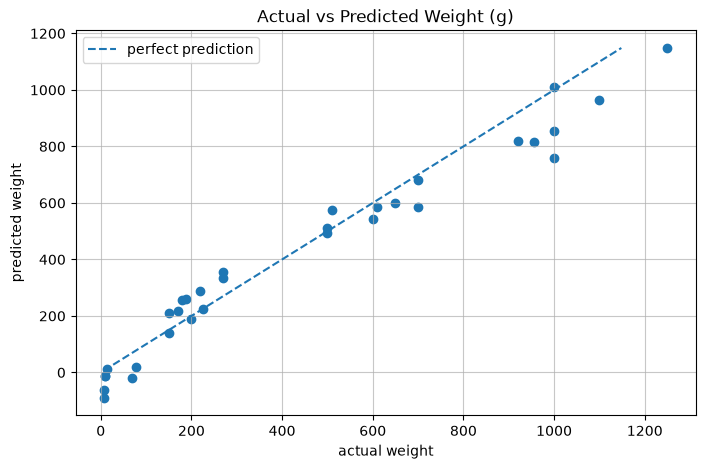

In [14]:
#        Training Plots

plt.figure(figsize=(8,5))
plt.scatter(y_test,y_pred)
plt.plot(
    [y_test.min(),y_pred.max()],
    [y_test.min(),y_pred.max()],
    linestyle = "--",
    label = "perfect prediction"
)
plt.xlabel("actual weight")
plt.ylabel("predicted weight")
plt.grid(alpha=0.70)
plt.title("Actual vs Predicted Weight (g)")
plt.legend()

plt.show()